# Actual image bytes: traditional and learned codecs

Four attributed photographs are compressed and decoded by JPEG, WebP, AVIF, JPEG2000, and four official pretrained learned architectures. Actual container size and precise displayed RGB8 reconstructions ground the comparison.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from PIL import Image as PILImage
from information_lab.images import encode, decode, metrics

original = np.array(PILImage.open(ROOT / "assets/images/originals/coffee.png").convert("RGB"))
encoded, details = encode(original, "jpeg", 60, ROOT / ".local/unused-image-cache")
restored = decode(encoded, "jpeg", ROOT / ".local/unused-image-cache")
print(
    "Actual JPEG bytes",
    len(encoded),
    "complete bpp",
    details["container_bpp"],
    metrics(original, restored),
)

Actual JPEG bytes 17822 complete bpp 1.4503580729166667 {'mse_rgb8': 47.017720540364586, 'psnr_db': 31.408187905396016, 'lossless_pixels': False, 'ssim_rgb': 0.8905214879906493, 'ms_ssim_rgb': 0.9816920161247253}


The learned examples use official pretrained weights, not new training on four pictures. Shared model weights are external and excluded from per-image bpp. Learned likelihood estimates, entropy payload and complete container costs are separate. Numeric quality points across codec families are not equivalent.

**Recorded configuration**

{
  "family": "images",
  "id": "coffee_cheng2020_anchor_3",
  "image": "coffee",
  "method": "cheng2020-anchor",
  "point": 3,
  "timing_repeats": 3,
  "stochastic": false
}
{
  "estimated_bpp": 0.24736613795782128,
  "payload_bpp": 0.24967447916666666,
  "model": {
    "architecture": "cheng2020-anchor",
    "quality": 3,
    "metric": "mse",
    "url": "https://compressai.s3.amazonaws.com/models/v1/cheng2020-anchor-3-e49be189.pth.tar",
    "checkpoint_sha256": "e49be189d829b71be8cc4e70206ba8510db87ed90180ebd6eea6c79e00554132"
  },
  "encode_seconds": 0.7187110744416714,
  "container_bpp": 0.2779947916666667,
  "mse_rgb8": 66.73542955186632,
  "psnr_db": 29.88723900658403,
  "lossless_pixels": false,
  "ssim_rgb": 0.8329659660053391,
  "ms_ssim_rgb": 0.9617247581481934,
  "decode_seconds": 1.4866119613870978,
  "encoded_bytes": 3416,
  "encoded_sha256": "846af35d7e9cd59bc6b9d64e391cb8bb99d7c0409e683c07c257a7be3c8d1878",
  "source_sha256": "a6de34c54d4d61de4ee0a93a3801504eb4ca088030cc

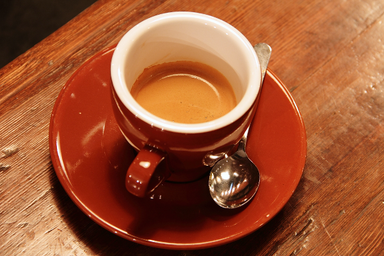

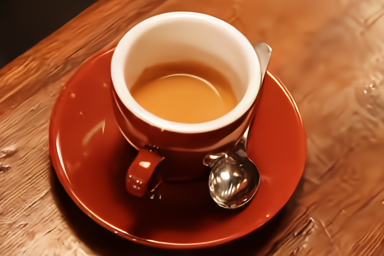

In [3]:
record, path = query("images", image="coffee", method="cheng2020-anchor", point=3)[0]
measured(record)
print("Original and actual decoded reconstruction:")
display(Image(filename=str(ROOT / "assets/images/originals/coffee.png")))
display(Image(filename=str(path / "decoded.png")))

In [4]:
data = arrays(path)
shown = np.array(PILImage.open(path / "decoded.png").convert("RGB"))
assert np.array_equal(shown, data["decoded"])
assert np.isclose(
    record["metrics"]["container_bpp"],
    8 * (path / "image.bin").stat().st_size / np.prod(shown.shape[:2]),
)
print("Gallery pixels exactly match saved numerical pixels and whole-file rate.")

Gallery pixels exactly match saved numerical pixels and whole-file rate.


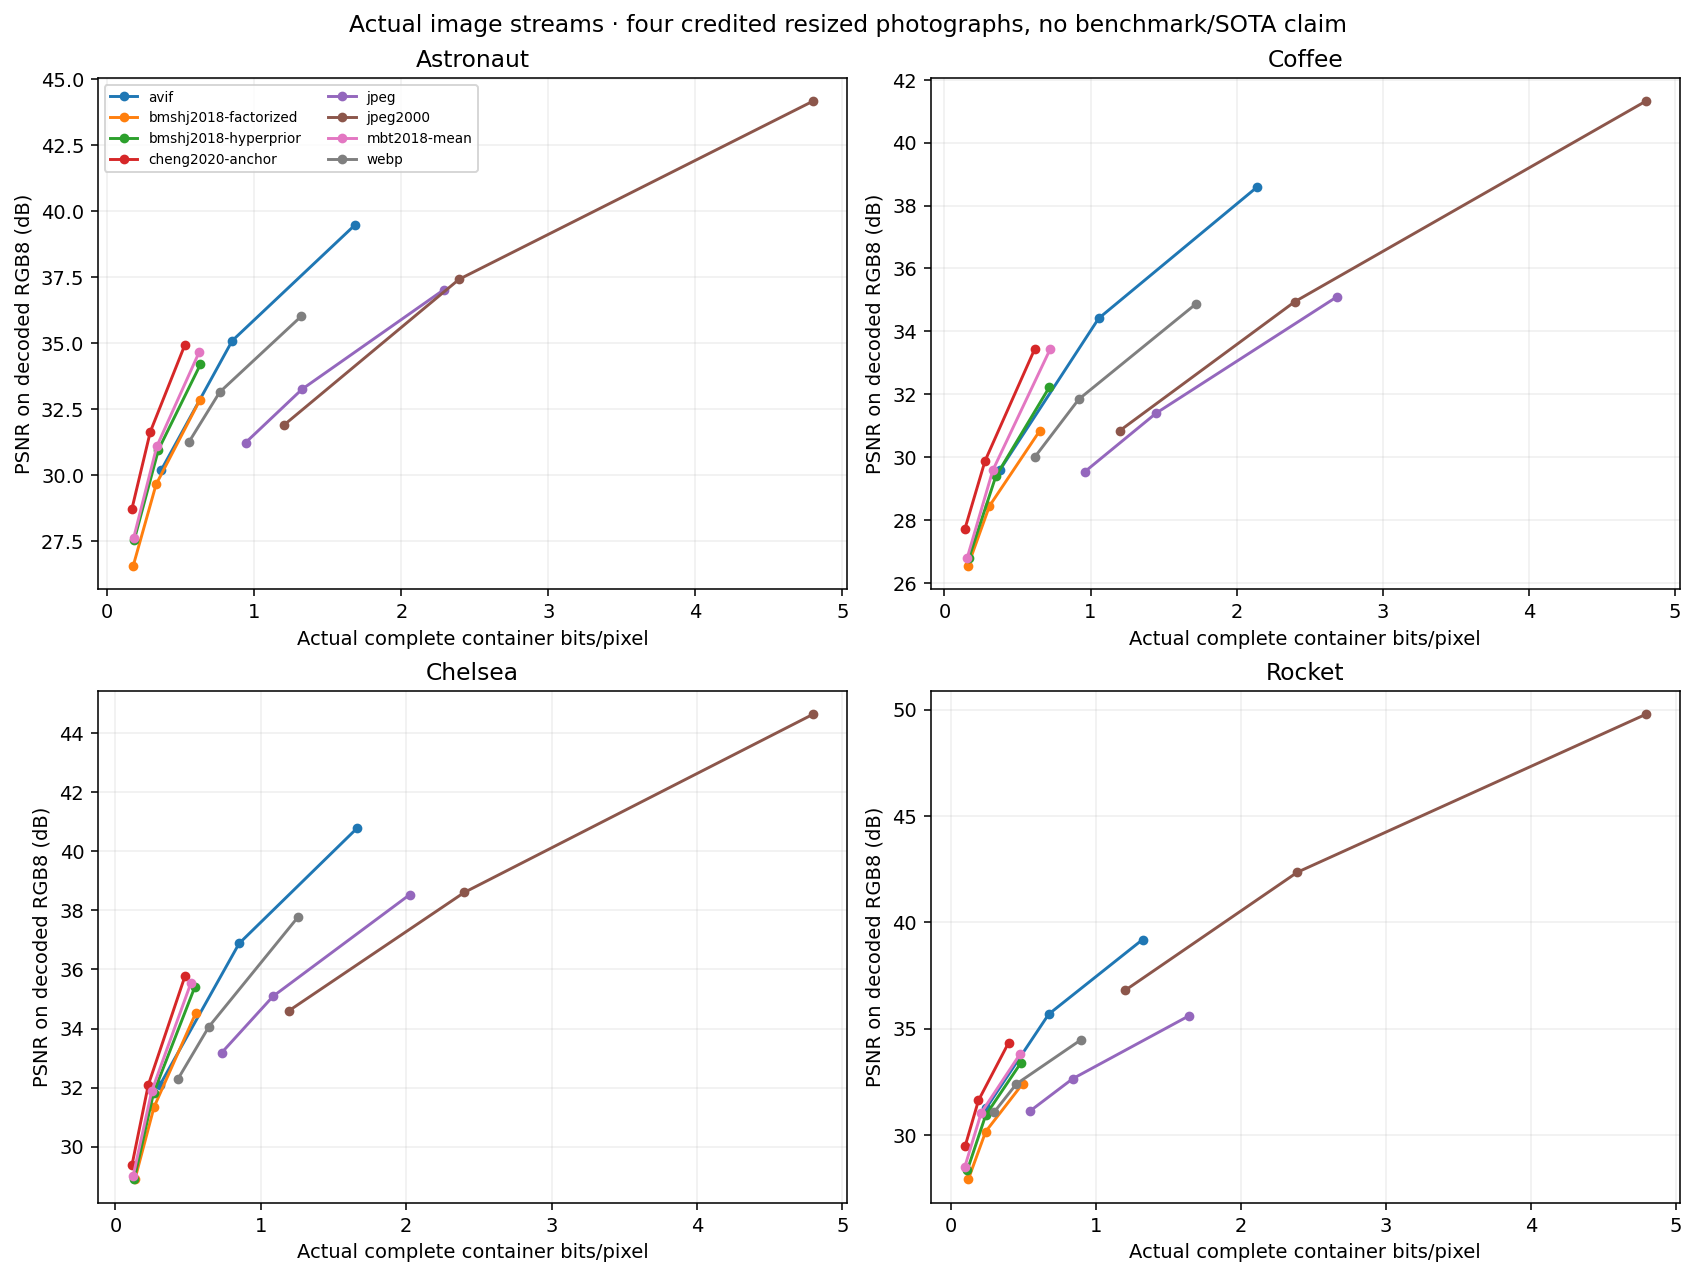

In [5]:
display(Image(filename=str(ROOT / "assets/previews/image_comparison.png")))

This small resized set demonstrates practical rate/quality tradeoffs; it does not establish a standard benchmark or current SOTA. The reference audit re-decodes all 96 stored streams using the cached official checkpoints. The notebook itself is offline: JPEG is encoded locally and learned reconstructions are inspected from the measured evidence.